# Practical Assignment: Clustering on a Real-World Dataset

**Name:** Tejal Vijay Kadam  
**Division:** A  
**Roll No.:** 36  
**PRN:** 202401040153

## Section 1: Import Libraries and Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

data = load_wine()
df = pd.DataFrame(data.data, columns=data.feature_names)
true_labels = data.target

print(df.shape)
df.head()

(178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## Section 2: Exploratory Data Analysis

In [2]:
print(df.isnull().sum().sum())
df.describe().T.round(2)

0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


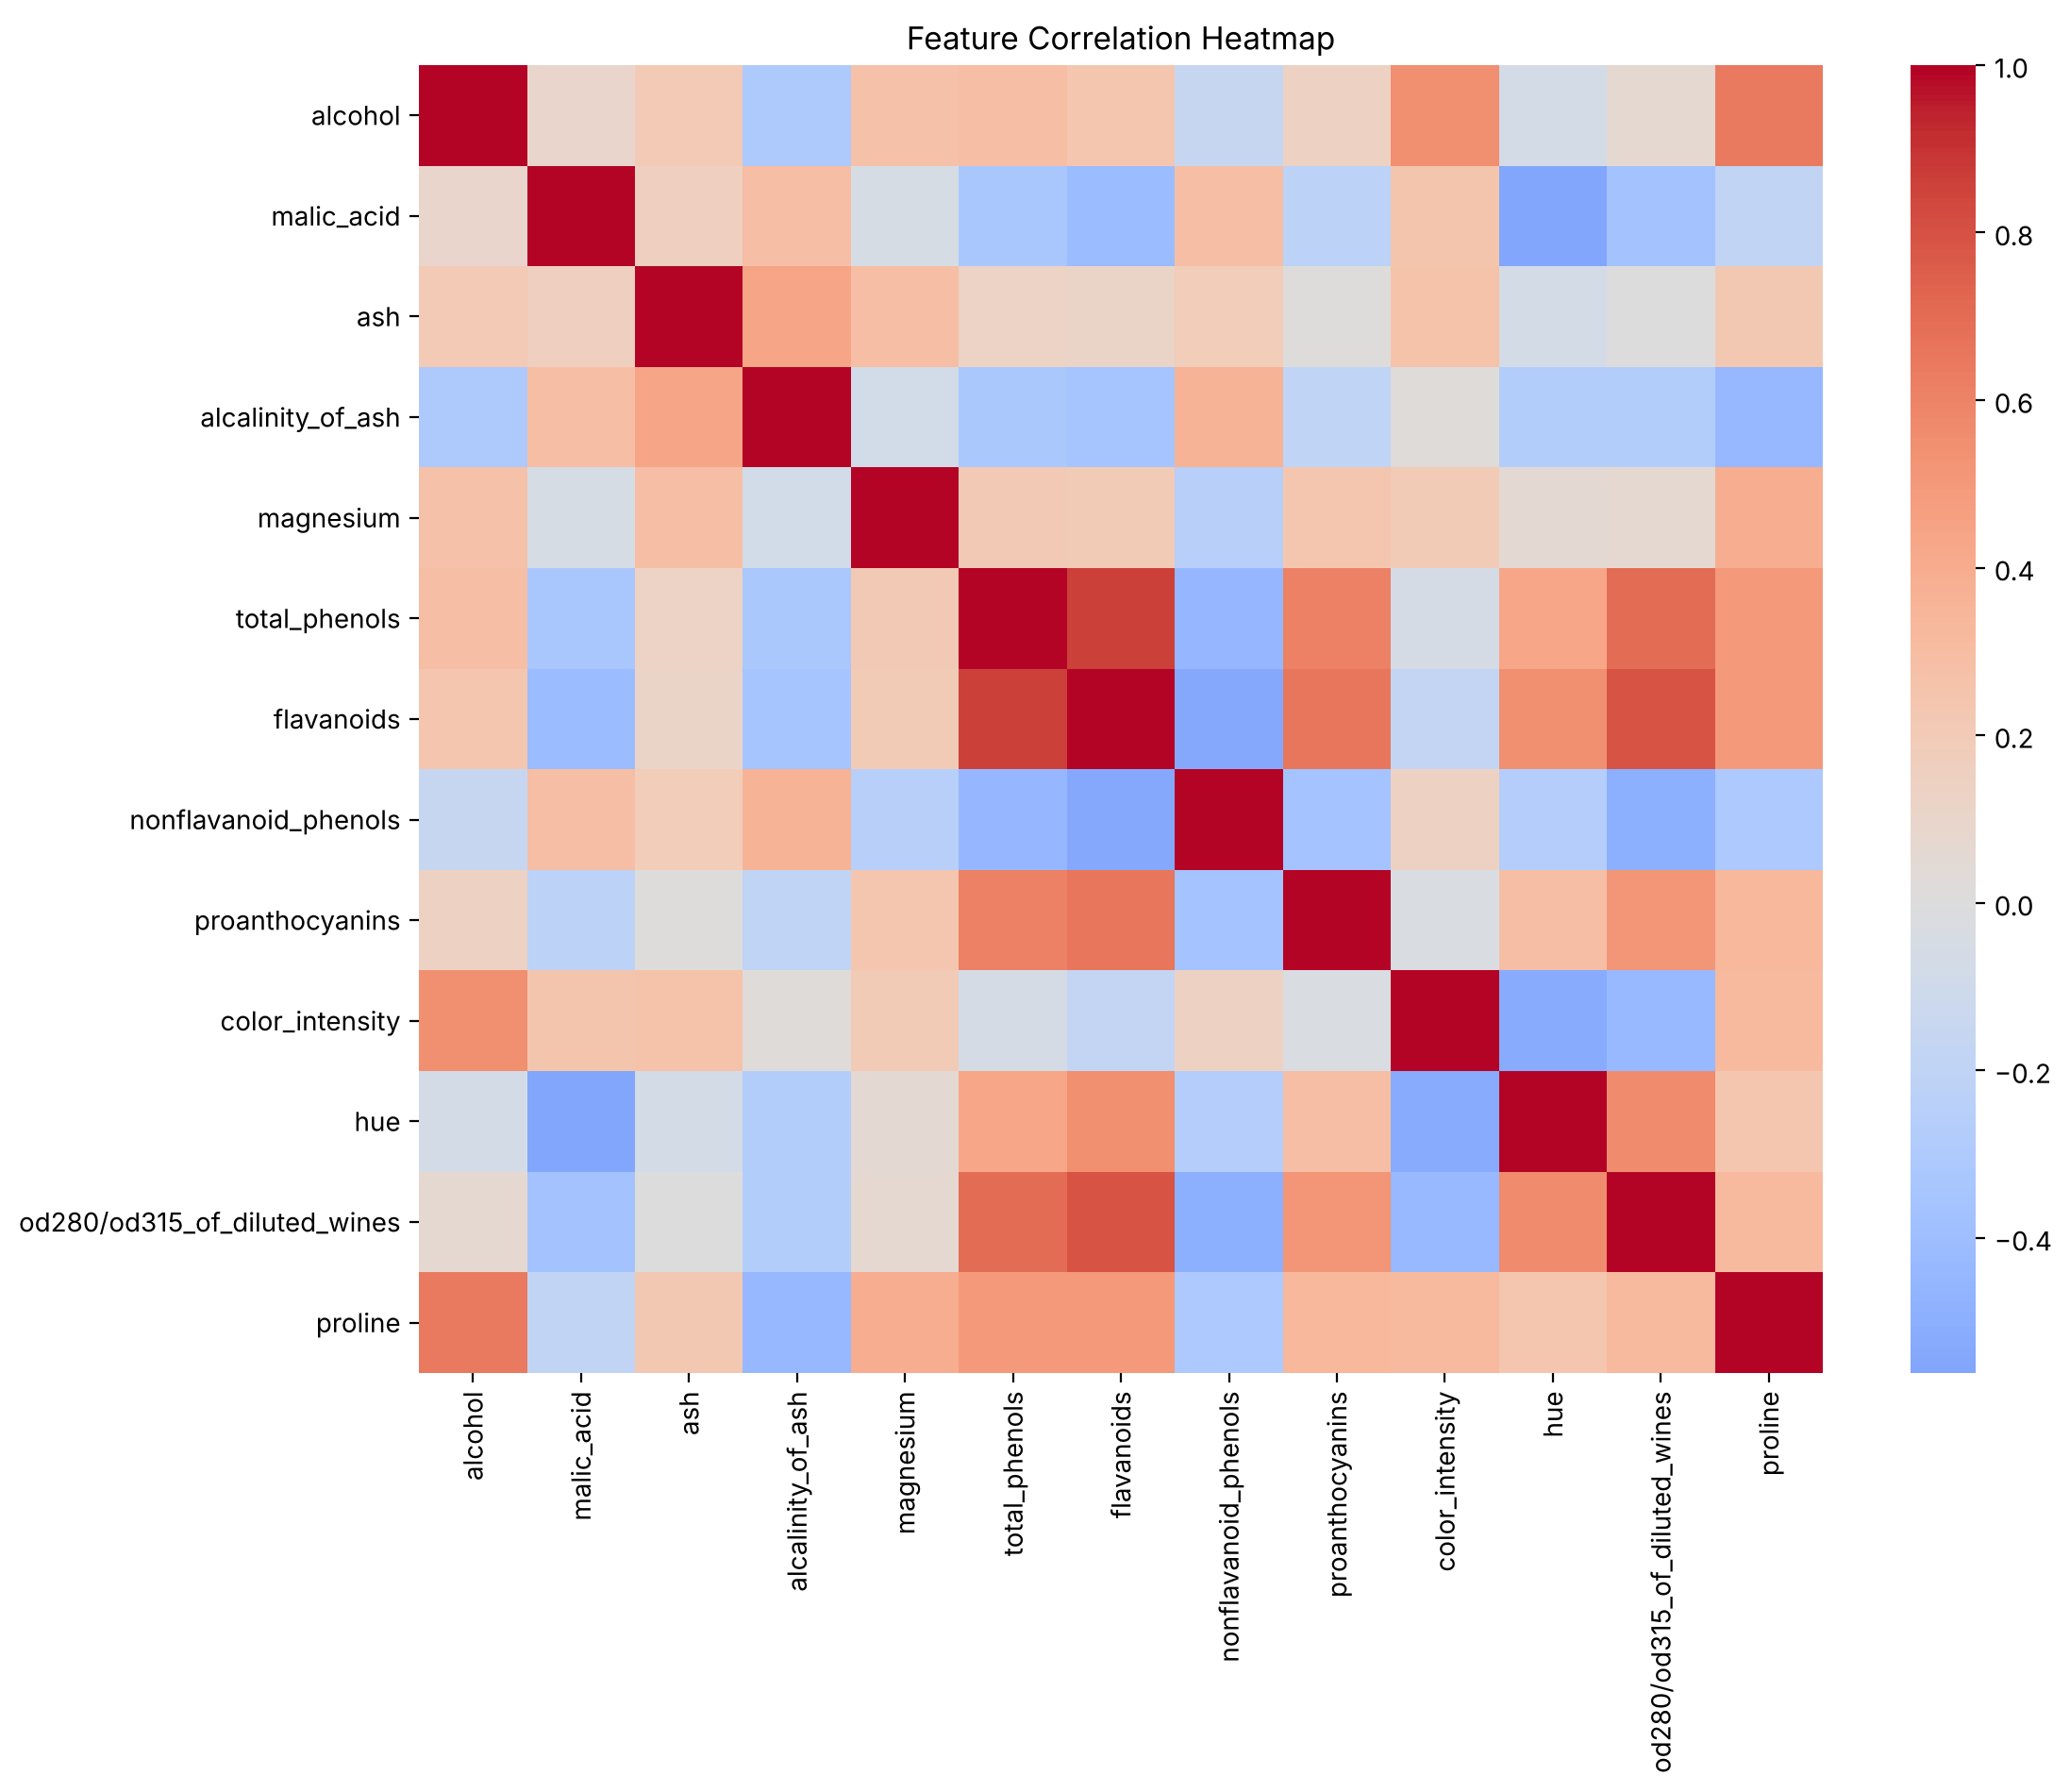

In [3]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.show()

## Section 3: Data Preprocessing (Scaling and PCA for Visualisation)

[0.362 0.192] 0.554


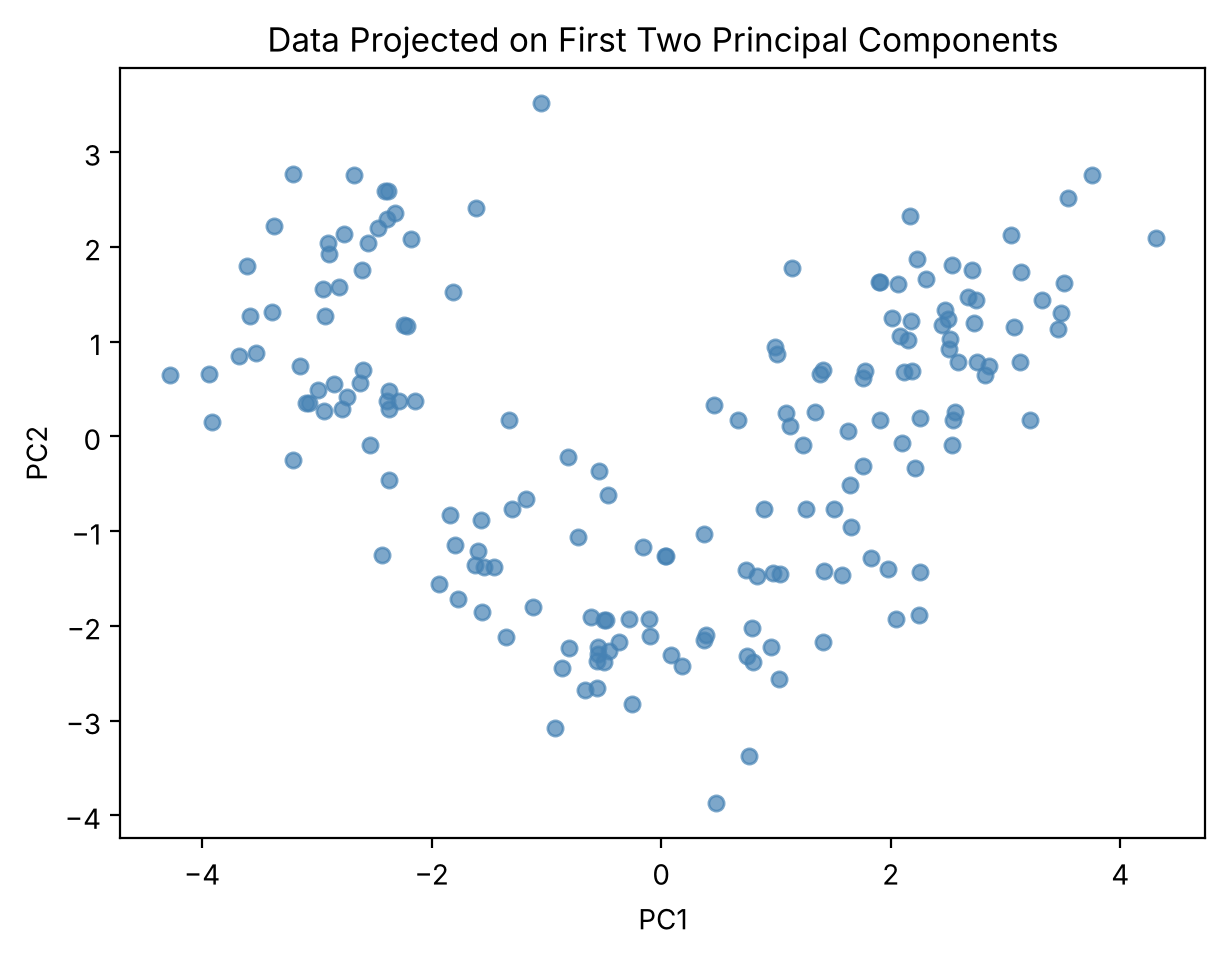

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(df)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print(pca.explained_variance_ratio_.round(3), pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=30, color='steelblue', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Data Projected on First Two Principal Components')
plt.show()

## Section 4: K-Means Clustering

### 4.1 Choosing the Number of Clusters (Elbow and Silhouette)

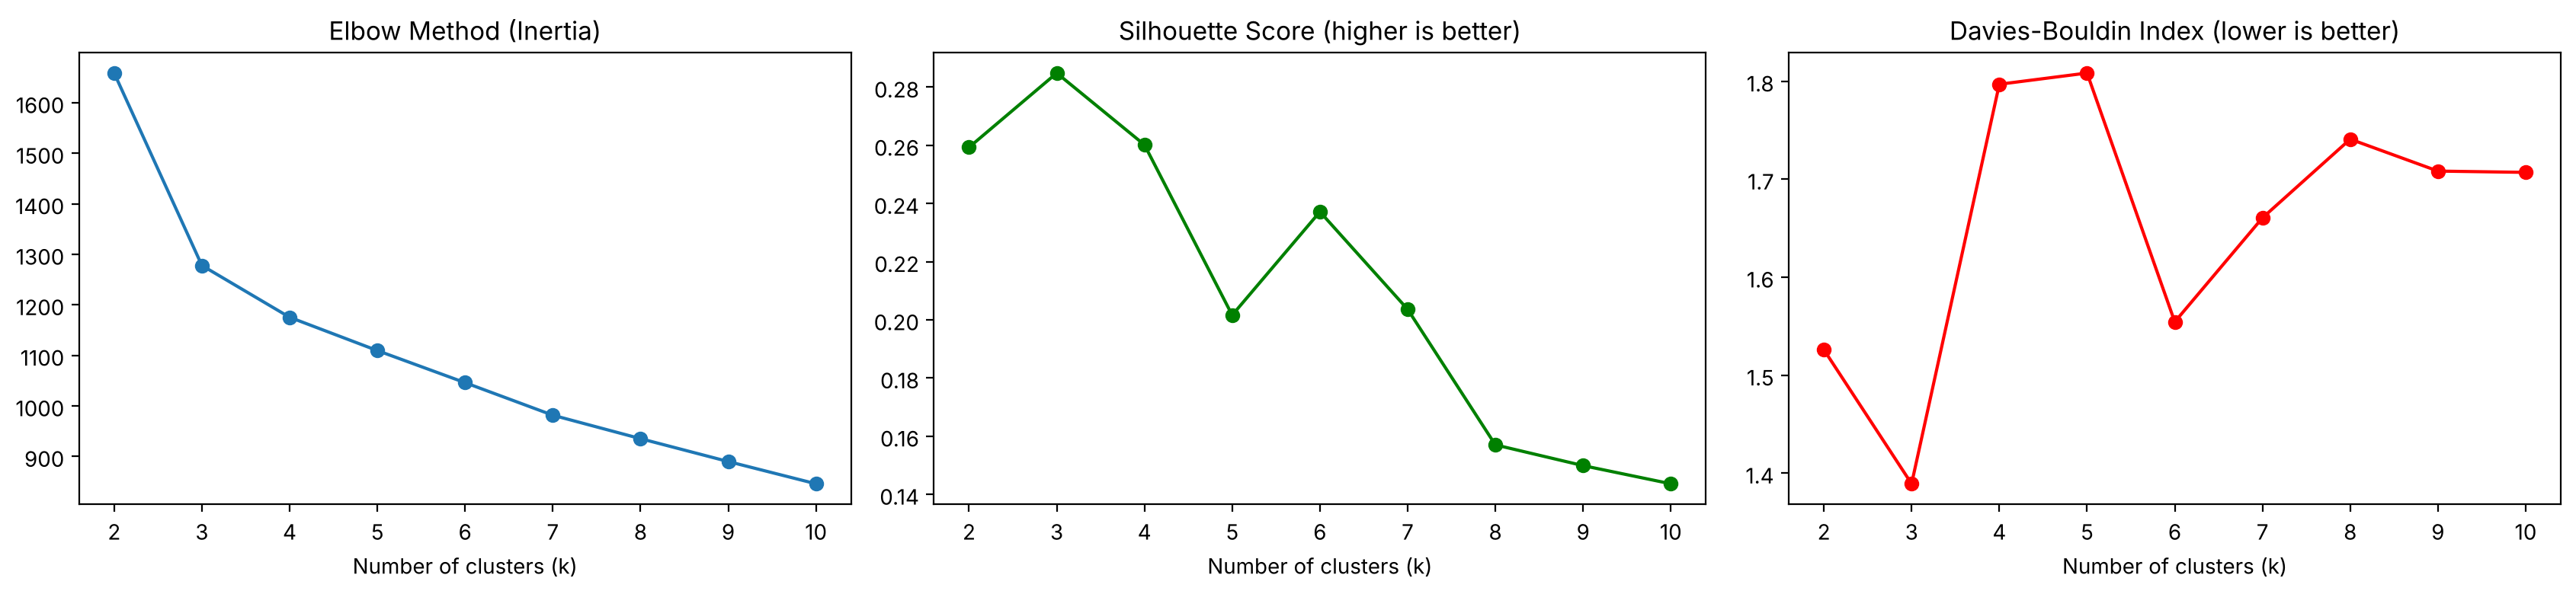

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,1658.7589,0.2593,1.5260,69.5233
1,3,1277.9285,0.2849,1.3892,70.9400
2,4,1175.4283,0.2602,1.7969,56.1814
3,5,1109.5127,0.2016,1.8083,46.9522
4,6,1046.0023,0.2372,1.5544,41.7008
5,7,981.5952,0.2036,1.6606,38.6855
6,8,935.2012,0.1570,1.7409,35.8053
7,9,889.8929,0.1499,1.7083,33.8066
8,10,845.8952,0.1436,1.7070,32.3972


In [5]:
k_range = range(2, 11)
inertia, sil, dbi, chi = [], [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    dbi.append(davies_bouldin_score(X, km.labels_))
    chi.append(calinski_harabasz_score(X, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(k_range, inertia, 'o-')
axes[0].set_title('Elbow Method (Inertia)')
axes[1].plot(k_range, sil, 'o-', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[2].plot(k_range, dbi, 'o-', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
for ax in axes:
    ax.set_xlabel('Number of clusters (k)')
plt.tight_layout()
plt.show()

pd.DataFrame({'k': list(k_range), 'Inertia': inertia, 'Silhouette': sil,
              'Davies-Bouldin': dbi, 'Calinski-Harabasz': chi}).round(4)

### 4.2 Final K-Means Model

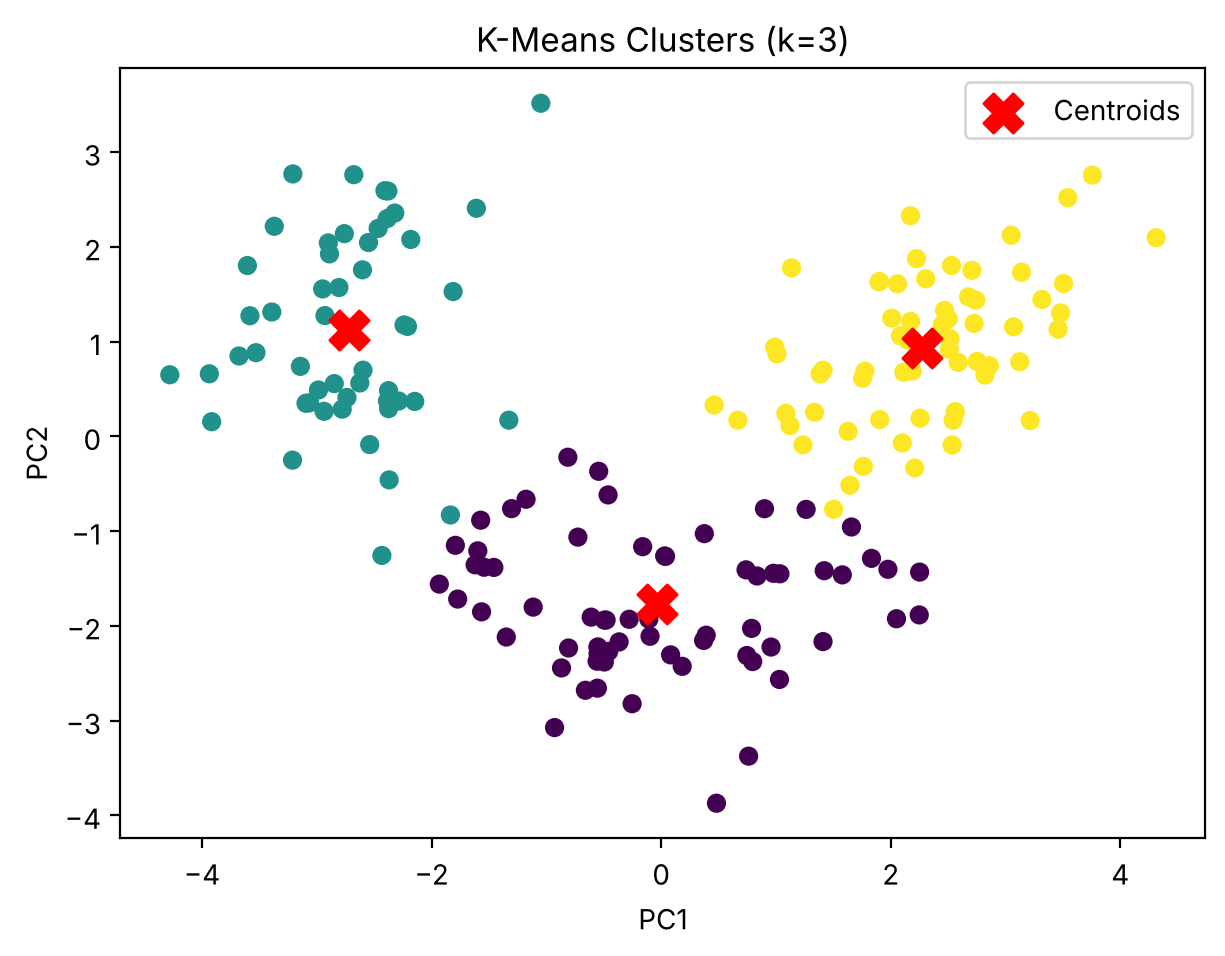

In [6]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=km_labels, cmap='viridis', s=35)
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.title('K-Means Clusters (k=3)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

## Section 5: Hierarchical (Agglomerative) Clustering

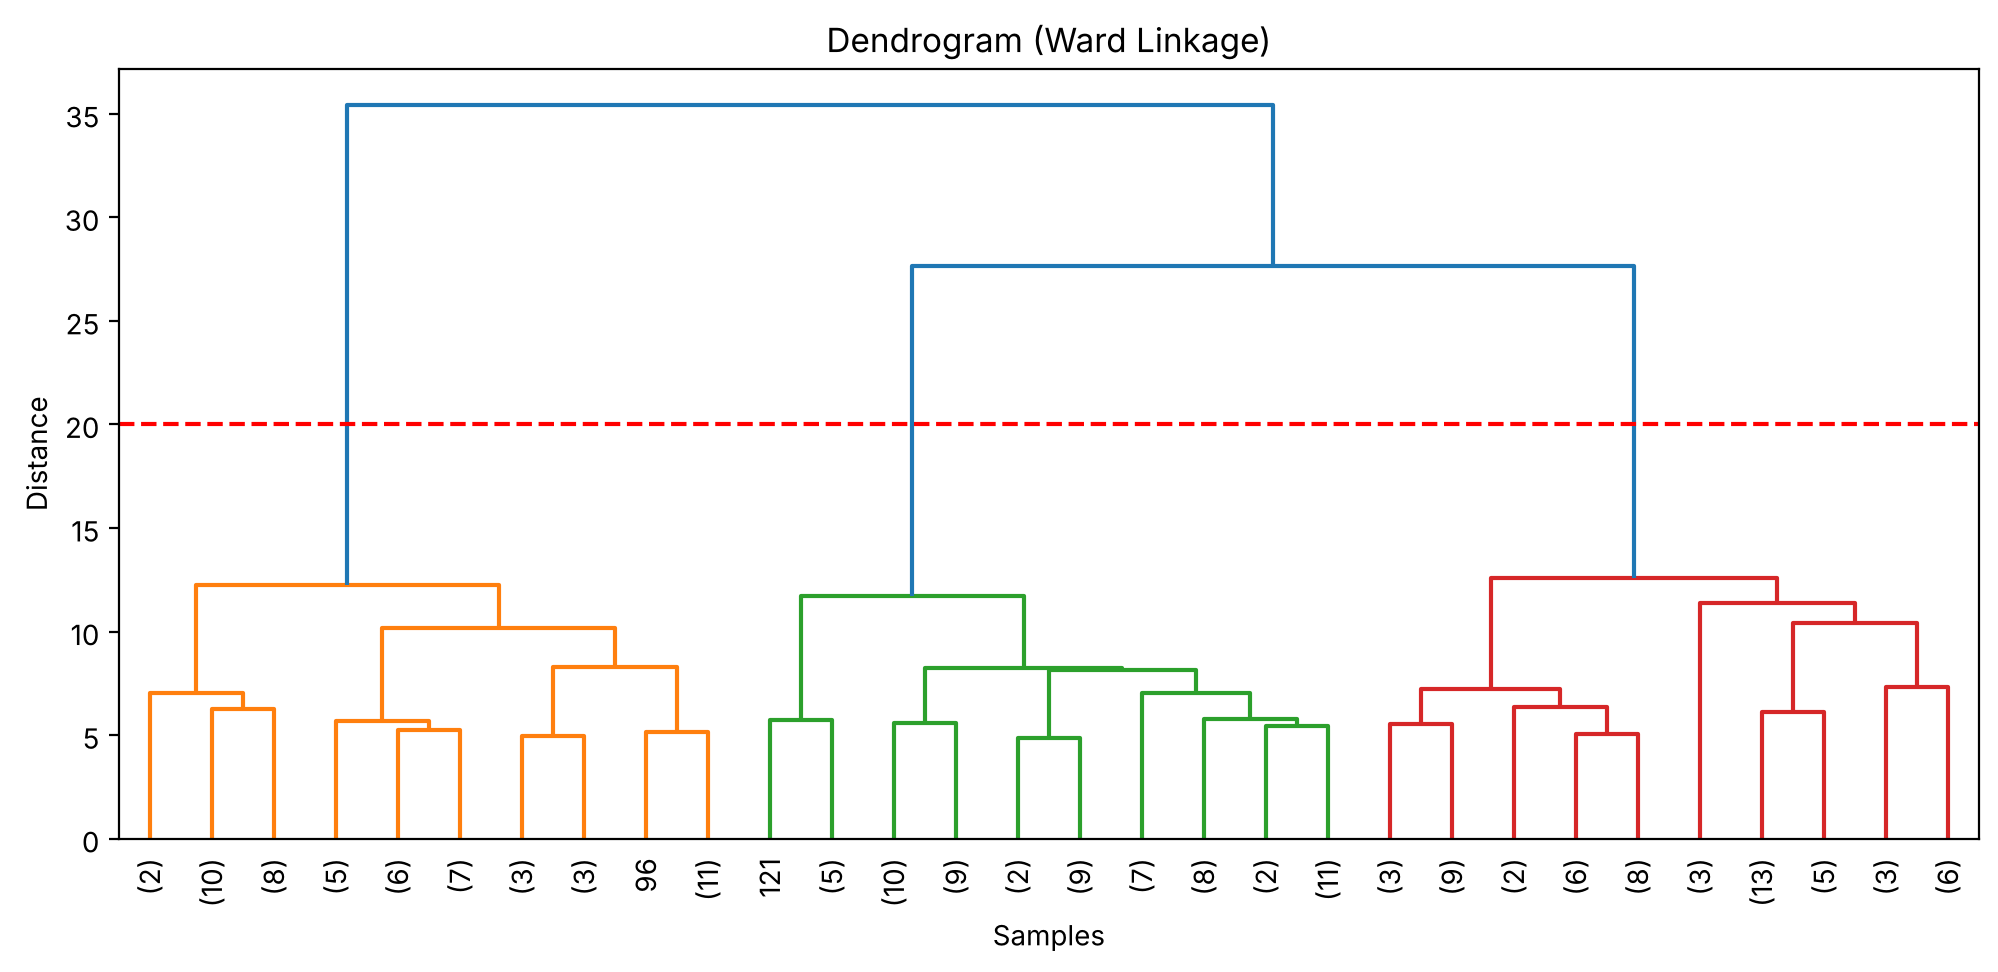

In [7]:
Z = linkage(X, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.axhline(y=20, color='red', linestyle='--')
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.show()

In [8]:
linkage_scores = {}
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X)
    linkage_scores[link] = silhouette_score(X, lab)

pd.Series(linkage_scores, name='Silhouette').round(4)

ward        0.2774
complete    0.2038
average     0.1575
single      0.1827
Name: Silhouette, dtype: float64

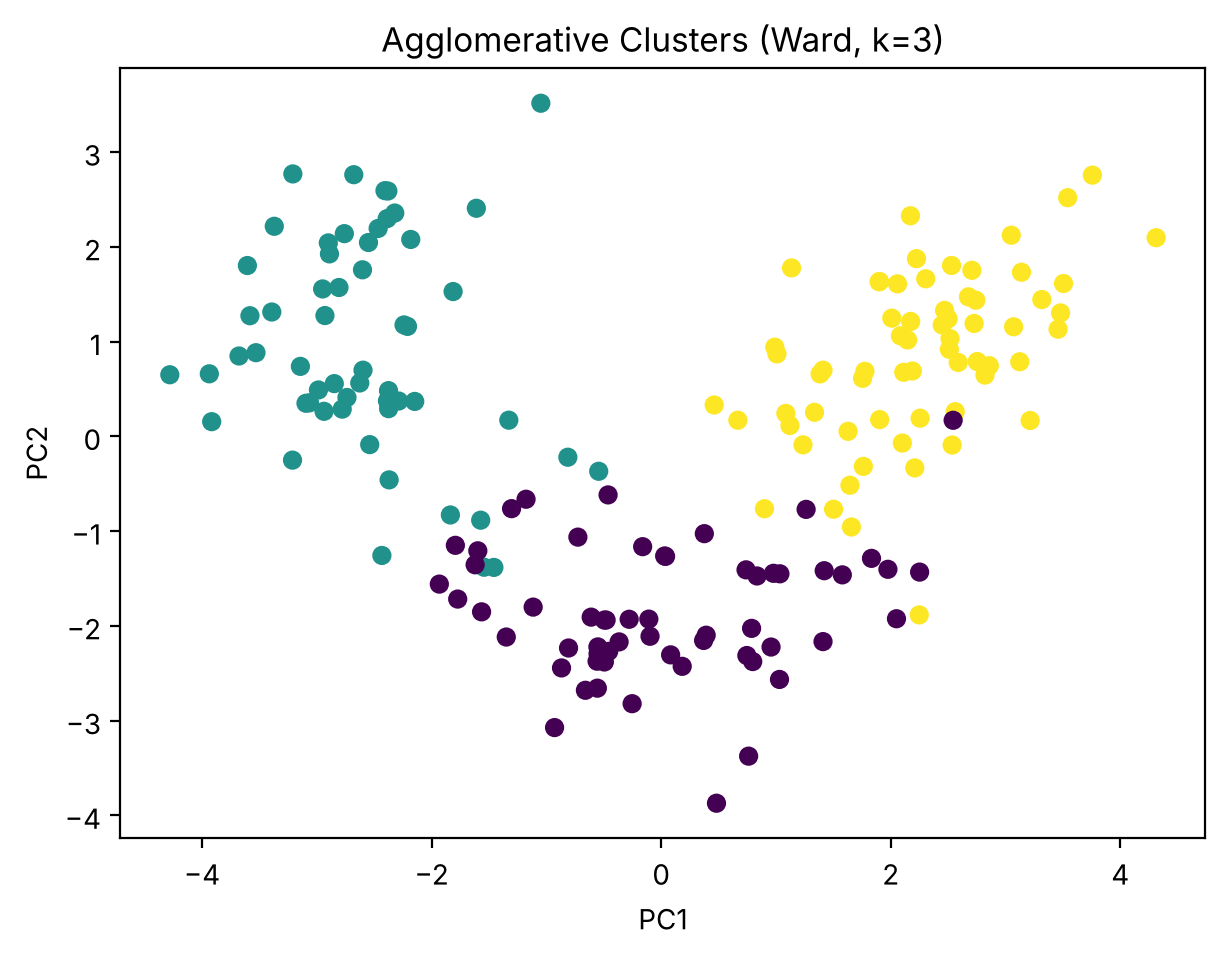

In [9]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='viridis', s=35)
plt.title('Agglomerative Clusters (Ward, k=3)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## Section 6: DBSCAN (Density-Based Clustering)

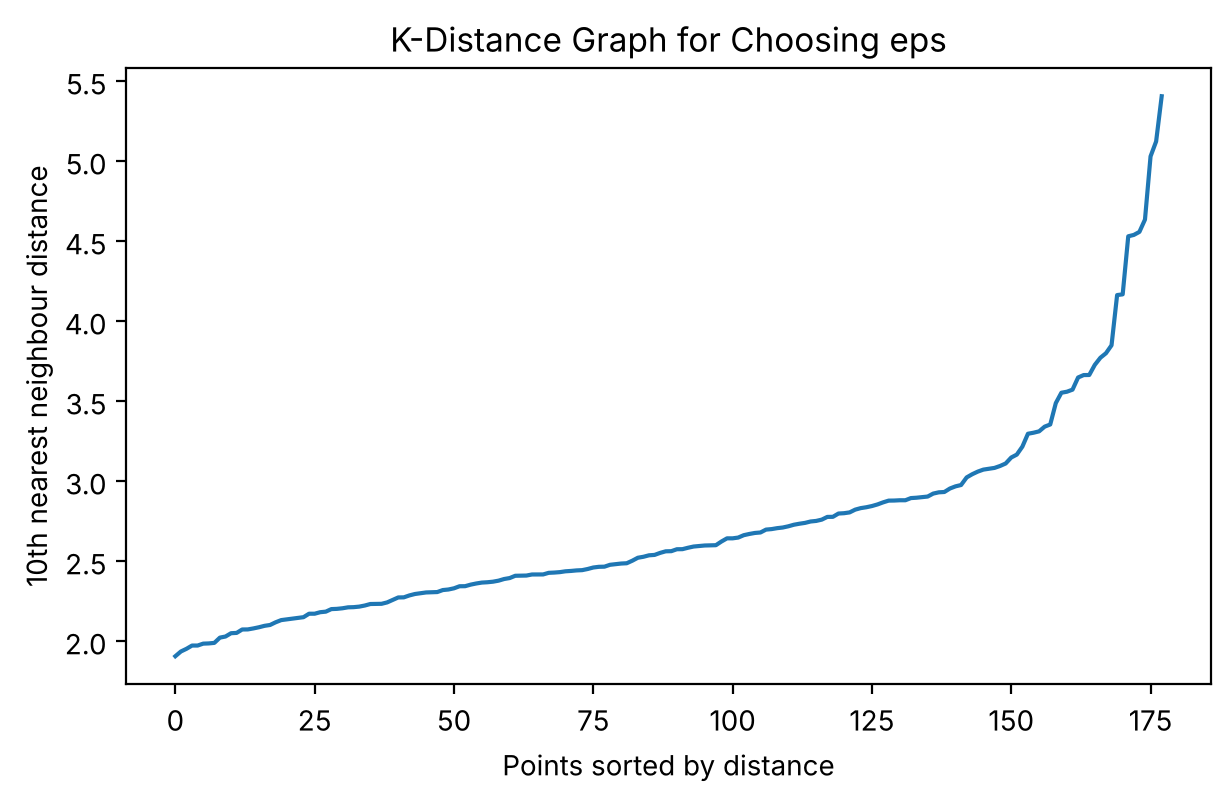

In [10]:
neighbors = NearestNeighbors(n_neighbors=10).fit(X)
distances, _ = neighbors.kneighbors(X)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.xlabel('Points sorted by distance')
plt.ylabel('10th nearest neighbour distance')
plt.title('K-Distance Graph for Choosing eps')
plt.show()

In [11]:
best = None
rows = []
for eps in np.arange(1.5, 3.6, 0.25):
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        if n_clusters >= 2:
            mask = lab != -1
            s = silhouette_score(X[mask], lab[mask])
            rows.append([round(eps, 2), ms, n_clusters, n_noise, s])
            if best is None or s > best[0]:
                best = (s, eps, ms)

dbscan_grid = pd.DataFrame(rows, columns=['eps', 'min_samples', 'clusters', 'noise_points', 'silhouette'])
dbscan_grid.sort_values('silhouette', ascending=False).head(8).round(4)

,eps,min_samples,clusters,noise_points,silhouette
5,2.00,8,3,117,0.4360
9,2.25,10,2,75,0.3783
8,2.25,8,2,61,0.3564
7,2.25,5,2,46,0.3371
6,2.25,3,2,37,0.3313
0,1.50,3,8,147,0.3311
11,2.50,10,2,32,0.3228
10,2.50,8,2,30,0.3183


[np.int64(-1), np.int64(0), np.int64(1)] 46


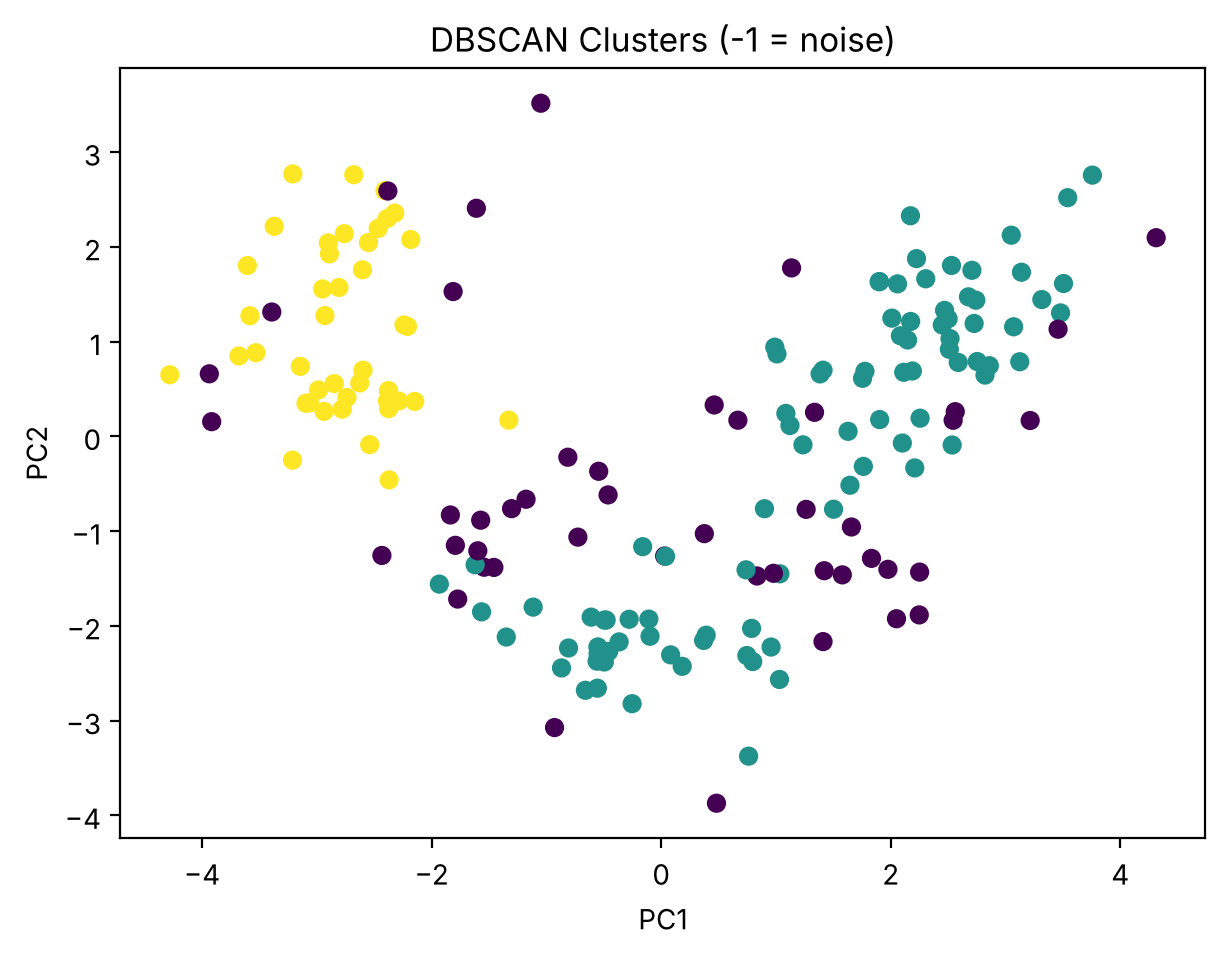

In [12]:
dbscan = DBSCAN(eps=2.25, min_samples=5)
db_labels = dbscan.fit_predict(X)

print(sorted(set(db_labels)), (db_labels == -1).sum())

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=db_labels, cmap='viridis', s=35)
plt.title('DBSCAN Clusters (-1 = noise)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## Section 7: Gaussian Mixture Model

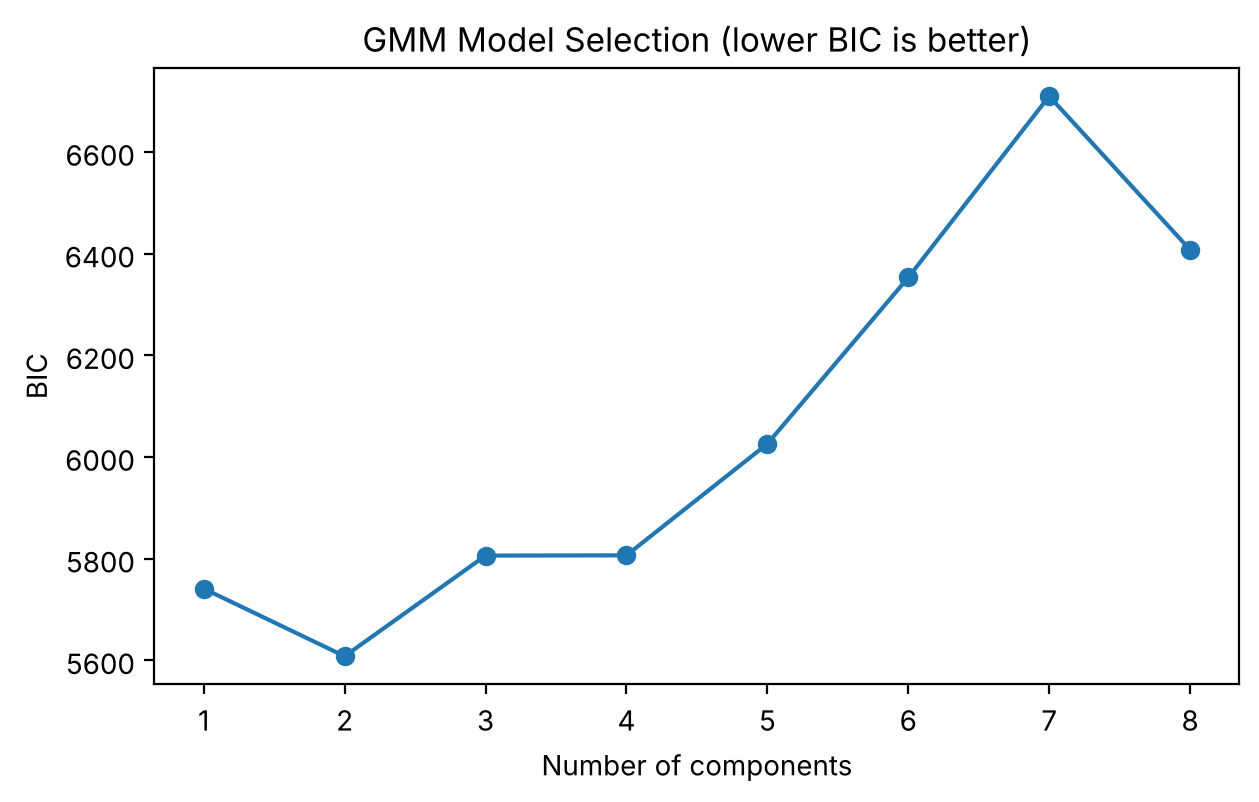

In [13]:
bic = []
for k in range(1, 9):
    gm = GaussianMixture(n_components=k, covariance_type='full', n_init=5, random_state=42).fit(X)
    bic.append(gm.bic(X))

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), bic, 'o-')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.title('GMM Model Selection (lower BIC is better)')
plt.show()

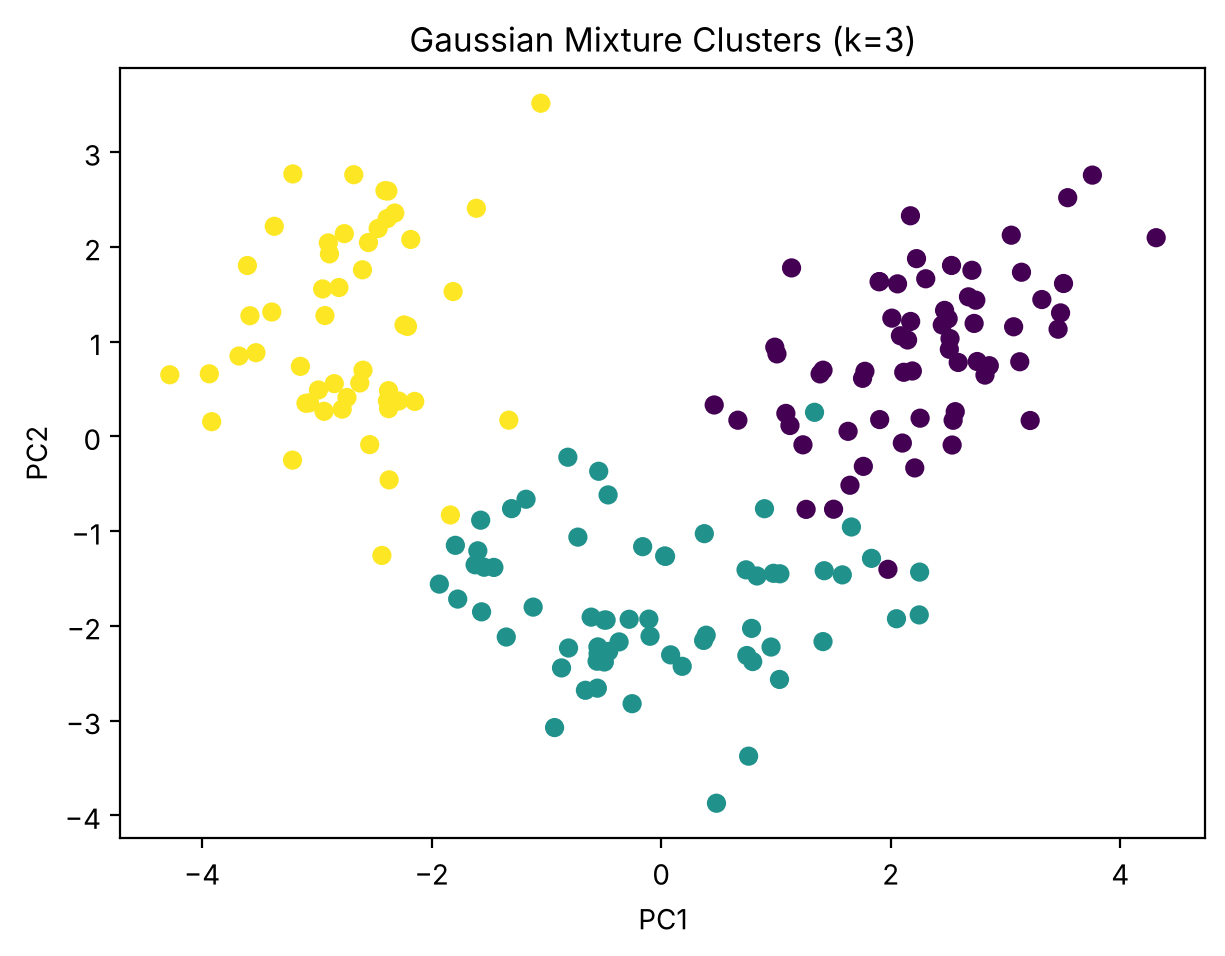

In [14]:
gmm = GaussianMixture(n_components=3, covariance_type='full', n_init=5, random_state=42)
gmm_labels = gmm.fit_predict(X)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='viridis', s=35)
plt.title('Gaussian Mixture Clusters (k=3)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## Section 8: Evaluation and Comparison of Clustering Quality

In [15]:
def evaluate(name, labels, exclude_noise=False):
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)
    n_clusters = len(set(labels[mask]))
    return {
        'Clusters': n_clusters,
        'Noise Points': int((~mask).sum()),
        'Silhouette': silhouette_score(X[mask], labels[mask]),
        'Davies-Bouldin': davies_bouldin_score(X[mask], labels[mask]),
        'Calinski-Harabasz': calinski_harabasz_score(X[mask], labels[mask]),
        'Adjusted Rand Index': adjusted_rand_score(true_labels[mask], labels[mask])
    }

evaluation = pd.DataFrame({
    'K-Means': evaluate('K-Means', km_labels),
    'Agglomerative (Ward)': evaluate('Agglomerative', agg_labels),
    'DBSCAN': evaluate('DBSCAN', db_labels, exclude_noise=True),
    'Gaussian Mixture': evaluate('GMM', gmm_labels)
}).T

evaluation.round(4)

,Clusters,Noise Points,Silhouette,Davies-Bouldin,Calinski-Harabasz,Adjusted Rand Index
K-Means,3.0,0.0,0.2849,1.3892,70.9400,0.8975
Agglomerative (Ward),3.0,0.0,0.2774,1.4186,67.6475,0.7899
DBSCAN,2.0,46.0,0.3371,1.1712,71.0774,0.5471
Gaussian Mixture,3.0,0.0,0.2844,1.3938,70.6878,0.8804


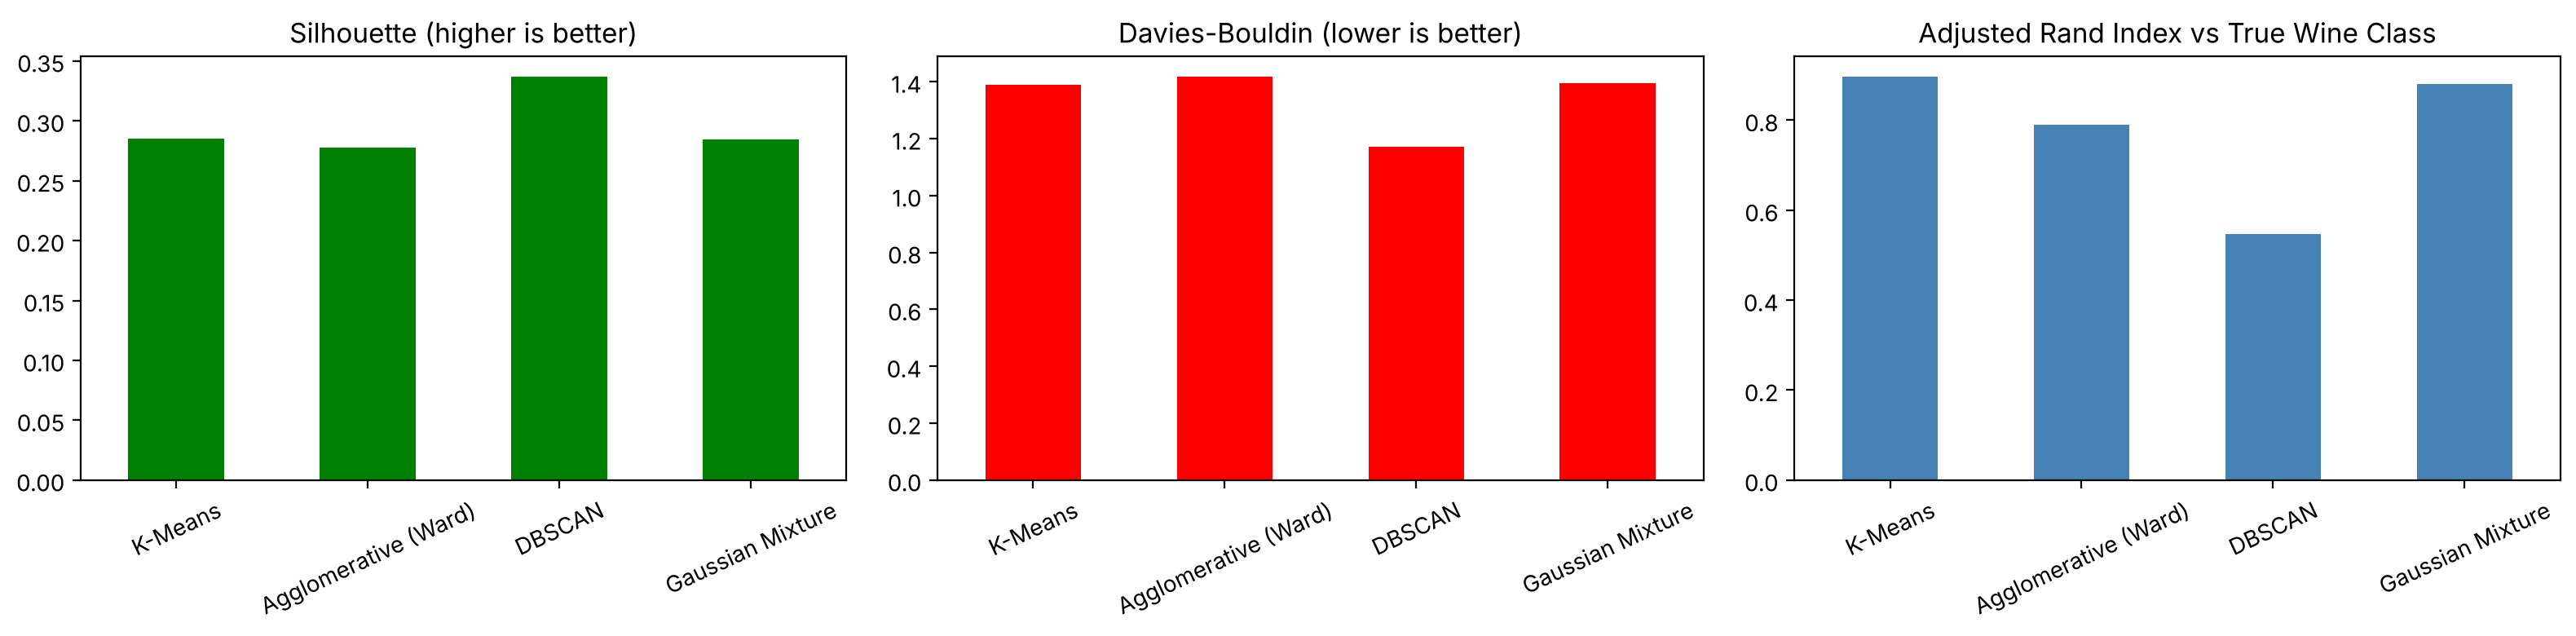

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
evaluation['Silhouette'].plot(kind='bar', ax=axes[0], color='green')
axes[0].set_title('Silhouette (higher is better)')
evaluation['Davies-Bouldin'].plot(kind='bar', ax=axes[1], color='red')
axes[1].set_title('Davies-Bouldin (lower is better)')
evaluation['Adjusted Rand Index'].plot(kind='bar', ax=axes[2], color='steelblue')
axes[2].set_title('Adjusted Rand Index vs True Wine Class')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

### 8.1 Silhouette Plot for K-Means

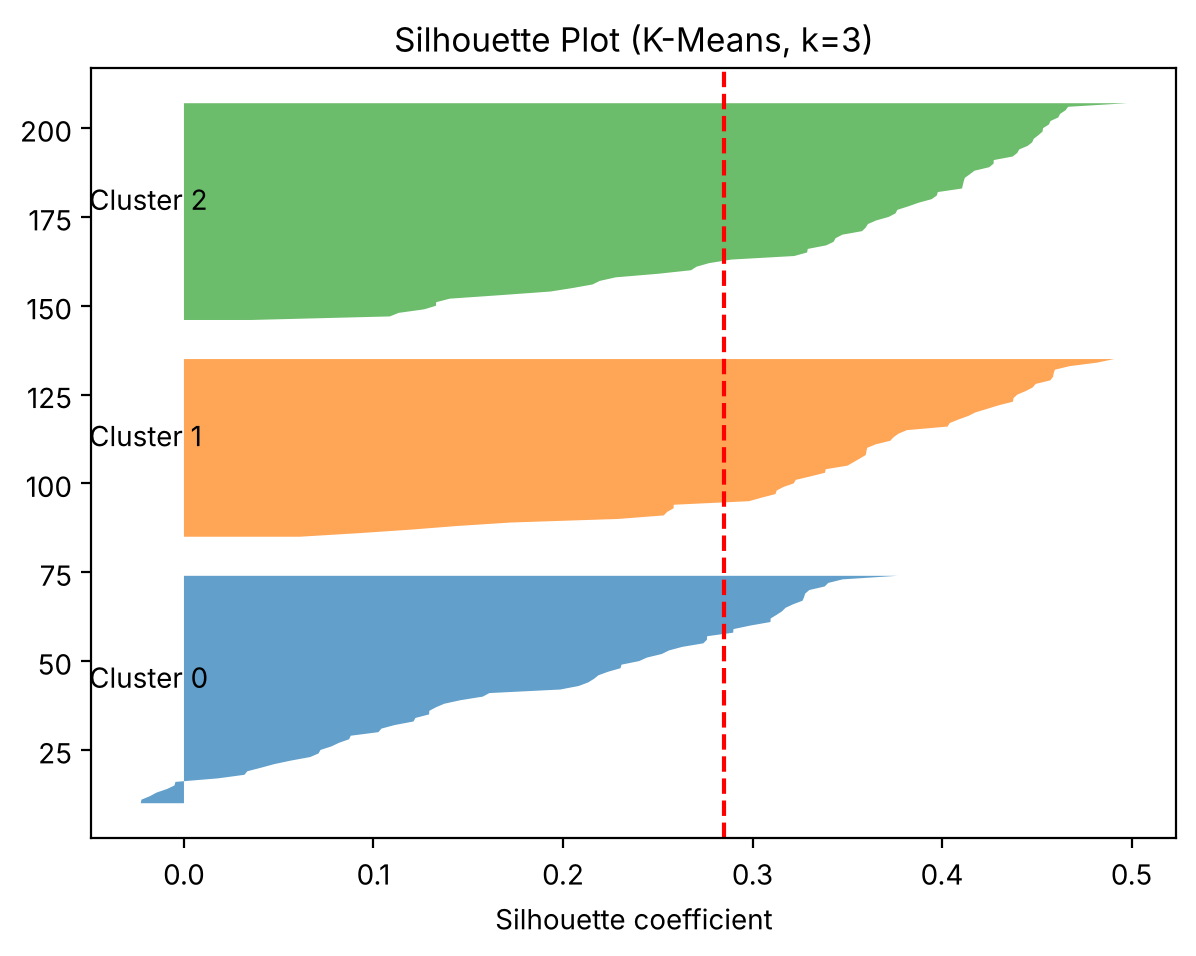

In [17]:
sil_vals = silhouette_samples(X, km_labels)
fig, ax = plt.subplots(figsize=(7, 5))
y_lower = 10
for i in range(3):
    vals = np.sort(sil_vals[km_labels == i])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * len(vals), f'Cluster {i}')
    y_lower = y_upper + 10
ax.axvline(silhouette_score(X, km_labels), color='red', linestyle='--')
ax.set_xlabel('Silhouette coefficient')
ax.set_title('Silhouette Plot (K-Means, k=3)')
plt.show()

### 8.2 Side-by-Side Visual Comparison

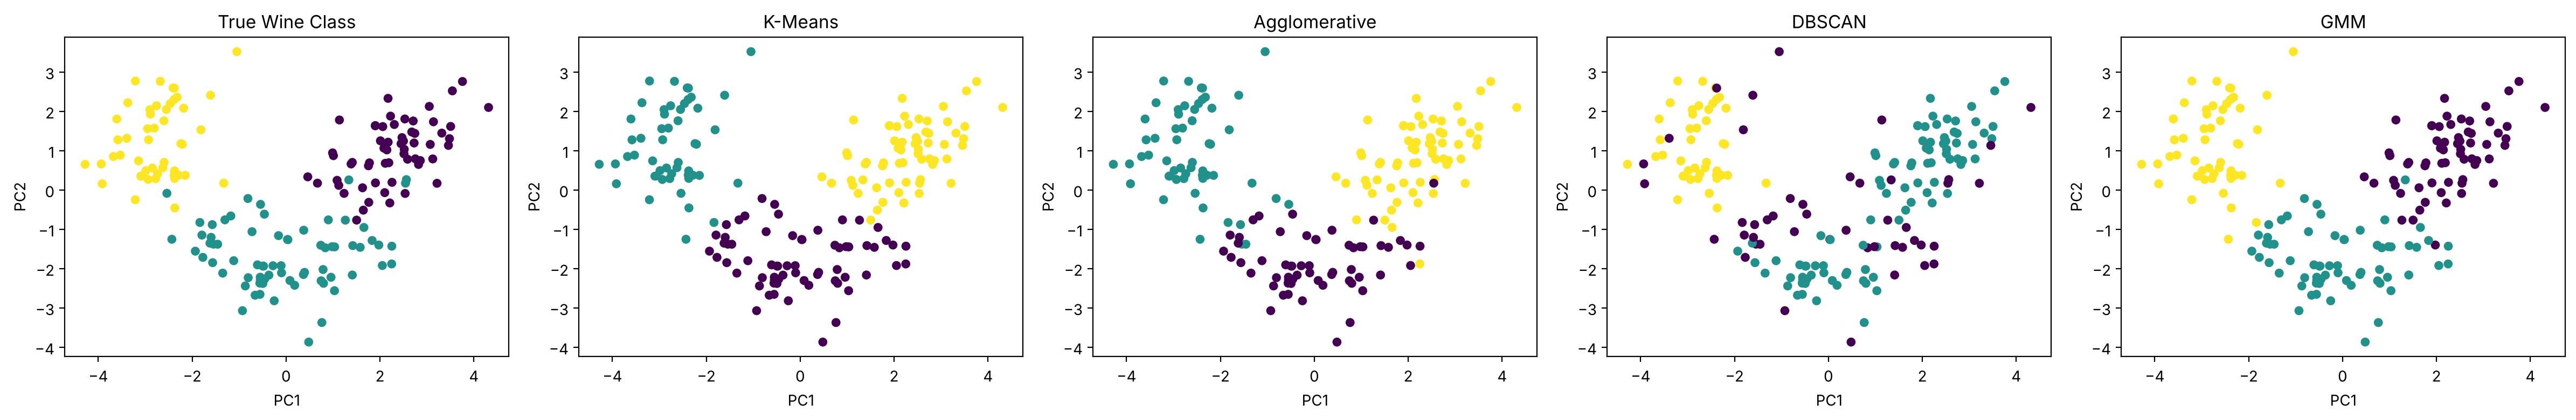

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4))
panels = [('True Wine Class', true_labels), ('K-Means', km_labels), ('Agglomerative', agg_labels),
          ('DBSCAN', db_labels), ('GMM', gmm_labels)]
for ax, (title, lab) in zip(axes, panels):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap='viridis', s=25)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

## Section 9: Cluster Profiling (Interpreting the Groups)

In [19]:
profile = df.copy()
profile['Cluster'] = km_labels
cluster_means = profile.groupby('Cluster').mean().round(2)
cluster_means.T

Cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


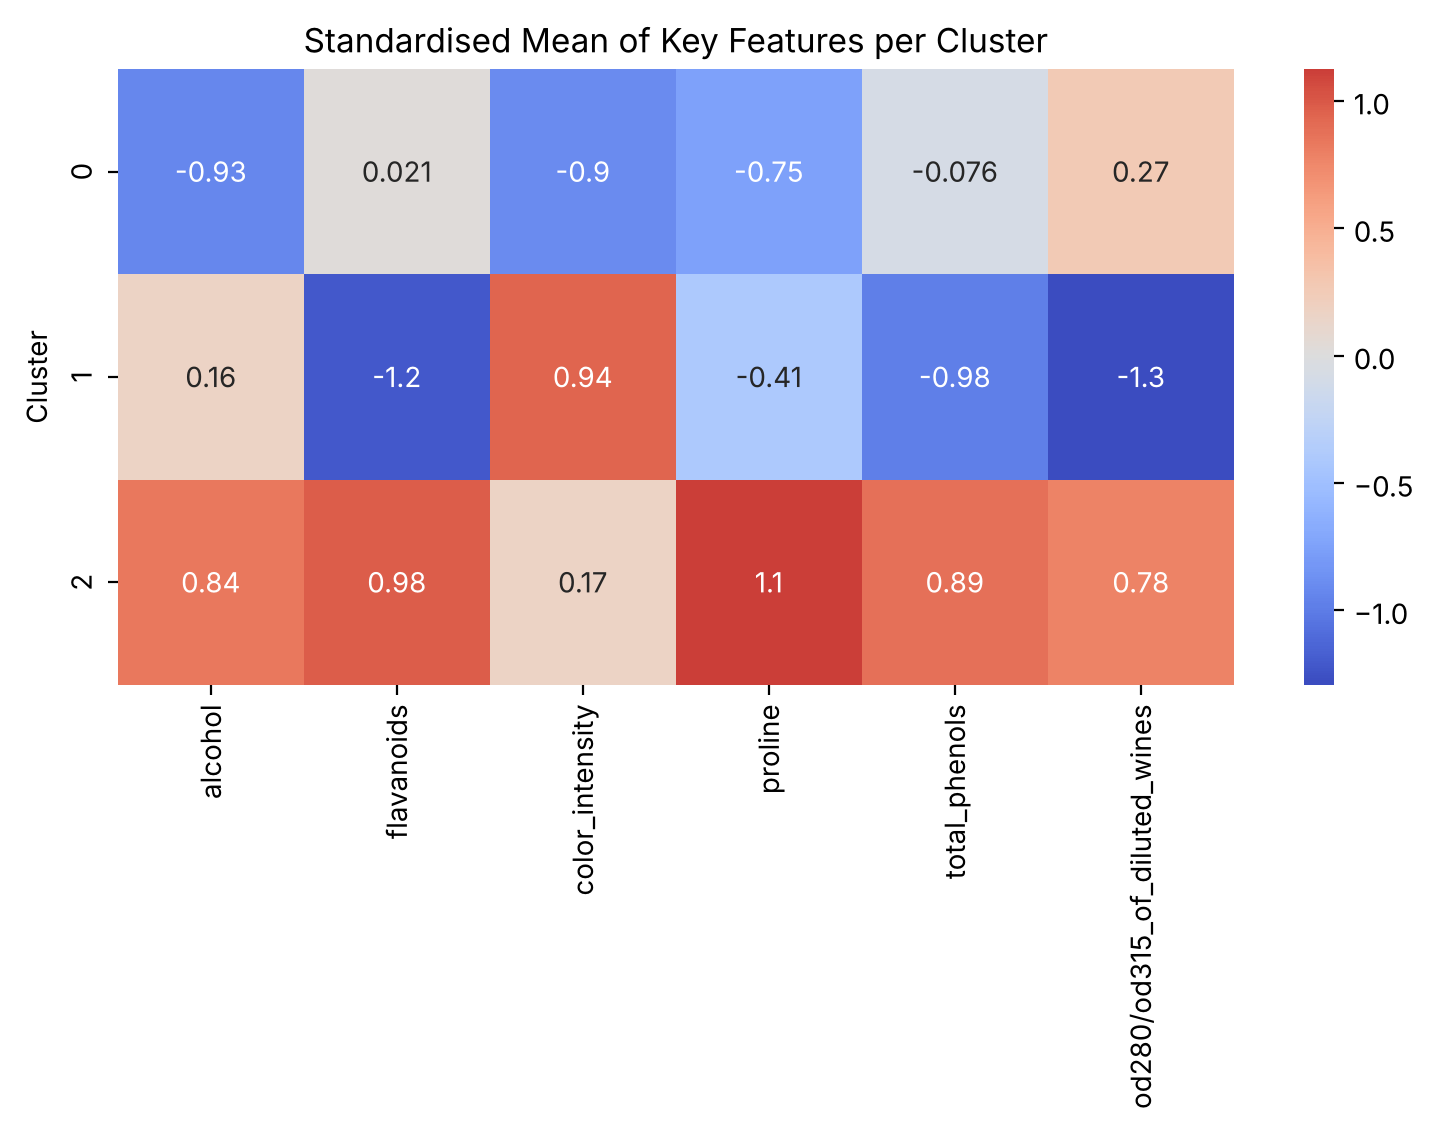

True Class,0,1,2
K-Means Cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


In [20]:
key_features = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'total_phenols', 'od280/od315_of_diluted_wines']
scaled_profile = pd.DataFrame(X, columns=df.columns)
scaled_profile['Cluster'] = km_labels

plt.figure(figsize=(9, 4))
sns.heatmap(scaled_profile.groupby('Cluster')[key_features].mean(), annot=True, cmap='coolwarm', center=0)
plt.title('Standardised Mean of Key Features per Cluster')
plt.show()

pd.crosstab(km_labels, true_labels, rownames=['K-Means Cluster'], colnames=['True Class'])

## Section 10: Summary, Findings and Future Work

### Dataset and Approach
The Wine dataset (178 samples, 13 chemical measurements of wines grown in Italy) was used. The features were standardised, and PCA (two components, 55.4% of the variance) was used only for plotting. Four algorithms were applied: K-Means, Agglomerative (Ward) clustering, DBSCAN and a Gaussian Mixture Model. The wine class labels were not used for clustering. They were used afterwards only to check the results with the Adjusted Rand Index (ARI).

### Choosing the Number of Clusters
- For K-Means, k = 3 had the highest silhouette score (0.2849), the lowest Davies-Bouldin index (1.3892) and the highest Calinski-Harabasz score (70.94) among the values of k tested. The elbow curve also bends around k = 3.
- The GMM was run with 1 to 8 components and BIC was used to choose the number of components, as shown in Section 7.

### Quality of Each Algorithm
| Algorithm | Clusters | Noise points | Silhouette | Davies-Bouldin | ARI |
|---|---|---|---|---|---|
| K-Means | 3 | 0 | 0.2849 | 1.3892 | 0.8975 |
| Agglomerative (Ward) | 3 | 0 | 0.2774 | 1.4186 | 0.7899 |
| DBSCAN (eps=2.25, min_samples=5) | 2 | 46 | 0.3371 | 1.1712 | 0.5471 |
| Gaussian Mixture | 3 | 0 | 0.2844 | 1.3938 | 0.8804 |

### Key Findings
- K-Means gave the best overall result. It has the highest ARI (0.8975) and a silhouette score and Davies-Bouldin index close to the best of the three-cluster methods. Its clusters match the true wine classes closely: only 6 of 178 wines were placed in a different group from their class.
- The Gaussian Mixture Model gave almost the same result as K-Means (silhouette 0.2844, ARI 0.8804), which shows the three groups are fairly round and well separated.
- Ward Agglomerative clustering was slightly weaker (ARI 0.7899). Complete, average and single linkage gave lower silhouette scores than Ward in Section 5.
- DBSCAN has the best silhouette (0.3371) and Davies-Bouldin (1.1712), but this is misleading. It was scored only on the 126 points it did not label as noise. It found 2 clusters instead of 3 and left 46 wines (about 26%) as noise, so its ARI is the lowest (0.5471). In the parameter search the highest silhouette (0.4360) came from a setting that labelled 117 points as noise, which is not useful. The wine data has clusters of similar density that touch each other, which suits DBSCAN poorly.
- All silhouette scores are low to moderate (0.28 to 0.34). The groups are real but overlap, particularly where one wine class borders another, so these scores are not a sign of failure.

### Cluster Profiles (K-Means)
- **Cluster 0:** low alcohol (12.25), low colour intensity (2.97) and the lowest proline (510). These are lighter wines.
- **Cluster 1:** high malic acid (3.31), the highest colour intensity (7.23), the lowest flavanoids (0.82) and a low hue (0.69). These are darker, more acidic wines with few phenols.
- **Cluster 2:** the highest alcohol (13.68), flavanoids (3.00), total phenols (2.85) and proline (1100.23). These are strong, phenol-rich wines.

### When to Use Each Algorithm
- **K-Means:** fast and simple, works well when clusters are compact and roughly round and k can be estimated, as here.
- **Agglomerative clustering:** useful when you want a dendrogram and a hierarchy of groups. It is slower on large datasets.
- **DBSCAN:** best when clusters have irregular shapes or the data has outliers. It needs careful choice of eps and min_samples and struggles when densities vary or clusters touch.
- **Gaussian Mixture:** useful when clusters overlap or are elliptical, and it gives soft membership probabilities.

### Conclusion
K-Means with k = 3 gave the most meaningful and well-supported grouping of the wine data, and the Gaussian Mixture Model agreed with it. Internal metrics (silhouette, Davies-Bouldin) should be read together with visual inspection and, where available, external labels, because DBSCAN scored well on the internal metrics while discarding a quarter of the data.

### Future Work and Improvements
- Try other algorithms such as K-Medoids, Spectral clustering, HDBSCAN or OPTICS.
- Test other feature scaling methods and feature selection, and remove highly correlated features before clustering.
- Use t-SNE or UMAP for visualisation instead of PCA only.
- Check cluster stability with bootstrapping or repeated runs with different random seeds.
- Apply the same workflow to a larger and noisier dataset, such as customer segmentation data, to see how the methods compare there.
